# Task 3: Siamese network for same-writer matching (and Task 4: evaluation design)

**Question:** given two digit images, were they written by the same person?

Unlike the CNN in Task 2, which can only name one of the 20 writers it was trained on, a Siamese
network learns a *similarity measure*. It can therefore compare writers it has **never seen**,
which is the realistic use (e.g. checking a questioned document against a known sample).

## Design (following the Keras triplet-loss example in the course notes)

- A shared **embedding CNN** maps each image to a 64-dimensional vector of length 1.
  The same weights are used for every input (that is what makes it "Siamese").
- **Triplet loss** (Schroff et al., 2015):
  $L(A,P,N) = \max\left(\lVert f(A)-f(P)\rVert^2 - \lVert f(A)-f(N)\rVert^2 + \text{margin},\ 0\right)$,
  margin = 0.5. The anchor *A* is pulled towards the positive *P* and pushed away from the negative *N*.
- At test time two images are called "same writer" when the squared distance between their
  embeddings is below a threshold.

## How training triplets are built

| | writer | digit | session |
|---|---|---|---|
| Anchor | random | random | random |
| Positive | **same** | **same** | **different** from anchor |
| Negative | **different** | **same** | random |

- **Digit is controlled** (all three images show the same digit). Otherwise the easiest way to
  reduce the loss is to learn digit shape, not handwriting style.
- **Positives come from a different session**, because EDA showed replicates within one session are
  near-copies. Same-session positives would teach the network to spot duplicates.
- A **fresh random set of 15,000 triplets** is drawn every epoch, so the network sees many
  different combinations.

## Split: writer-disjoint, 5 folds (Task 4)

The 20 writers are shuffled and cut into 5 groups of 4. In fold *k*, group *k* is the **test** set,
group *k+1* is the **validation** set (early stopping and choosing the decision threshold) and the
remaining 12 writers are used for **training**. Every writer is tested exactly once, and test
writers are never seen during training.

In [1]:
import sys
sys.path.append("../src")
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_utils import load_handwriting
from siamese import (make_index_table, sample_triplets, make_pairs, train_siamese, embed,
                     pair_distance, verification_metrics)

images, meta = load_handwriting()
x = images[..., None]
X_flat = images.reshape(len(images), -1)
table = make_index_table(meta)        # table[person, digit, session, replicate] -> row
Path("../results").mkdir(exist_ok=True)

writers = np.random.default_rng(0).permutation(np.arange(1, 21))
groups = writers.reshape(5, 4)
folds = []
for k in range(5):
    test_w, val_w = groups[k], groups[(k + 1) % 5]
    train_w = np.setdiff1d(writers, np.r_[test_w, val_w])
    folds.append((train_w, val_w, test_w))
    print(f"fold {k}: test {sorted(test_w)}  validation {sorted(val_w)}")

I0000 00:00:1792106233.475033     376 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792106234.553115     376 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


fold 0: test [np.int64(3), np.int64(5), np.int64(7), np.int64(20)]  validation [np.int64(4), np.int64(12), np.int64(14), np.int64(17)]
fold 1: test [np.int64(4), np.int64(12), np.int64(14), np.int64(17)]  validation [np.int64(1), np.int64(9), np.int64(11), np.int64(13)]
fold 2: test [np.int64(1), np.int64(9), np.int64(11), np.int64(13)]  validation [np.int64(6), np.int64(8), np.int64(18), np.int64(19)]
fold 3: test [np.int64(6), np.int64(8), np.int64(18), np.int64(19)]  validation [np.int64(2), np.int64(10), np.int64(15), np.int64(16)]
fold 4: test [np.int64(2), np.int64(10), np.int64(15), np.int64(16)]  validation [np.int64(3), np.int64(5), np.int64(7), np.int64(20)]


### Example training triplets (anchor, positive, negative)

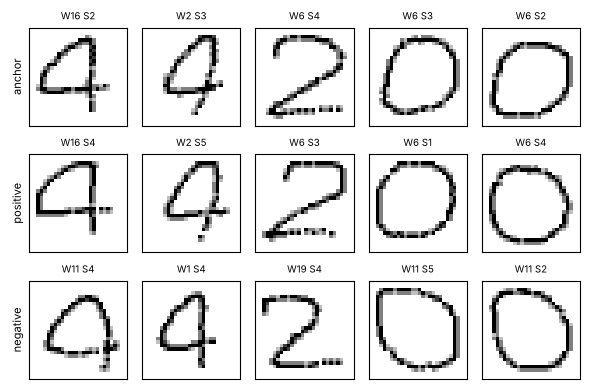

In [2]:
a, p, n = sample_triplets(table, folds[0][0], np.arange(1, 6), 5, np.random.default_rng(3))
fig, axes = plt.subplots(3, 5, figsize=(6, 4))
for j in range(5):
    for i, (idx, name) in enumerate([(a, "anchor"), (p, "positive"), (n, "negative")]):
        row = meta.iloc[idx[j]]
        axes[i, j].imshow(images[idx[j]], cmap="gray_r")
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        axes[i, j].set_title(f"W{row.person_id} S{row.session}", fontsize=7)
        if j == 0:
            axes[i, j].set_ylabel(name, fontsize=8)
plt.tight_layout()
plt.show()

## Train and evaluate each fold

Test pairs (6,000 per type, half same-writer, half different-writer), drawn **only from the 4 test writers**:

- **different session, same digit** (main measure): the realistic comparison.
- **same session, same digit**: near-duplicate positives, to show how optimistic this would be.
- **different digits**: e.g. a writer's 2 against their 4, to see whether the embedding captures
  style beyond one digit's shape.

The decision threshold is the equal-error-rate threshold on the **validation** writers, then applied
unchanged to the test writers. A **raw-pixel baseline** (distance between the images themselves)
shows what the network adds.

In [3]:
fold_rows, digit_rows, histories, fold0 = [], [], [], None

for k, (train_w, val_w, test_w) in enumerate(folds):
    print(f"\n=== fold {k} ===")
    v1, v2, v_label, _ = make_pairs(table, val_w, 4000, np.random.default_rng(100 + k))

    def val_auc(embedding):
        e = embed(embedding, x[np.r_[v1, v2]])
        return verification_metrics(((e[:len(v1)] - e[len(v1):]) ** 2).sum(1), v_label)["AUC"]

    embedding, hist = train_siamese(x, table, train_w, np.arange(1, 6), val_auc,
                                    n_triplets=15000, max_epochs=15, patience=3, seed=k)
    histories.append(pd.DataFrame(hist).assign(fold=k))
    emb = embed(embedding, x)

    threshold = verification_metrics(pair_distance(emb, v1, v2), v_label)["threshold"]
    rng = np.random.default_rng(200 + k)
    for mode in ["diff_session", "same_session", "diff_digit"]:
        i1, i2, label, digit = make_pairs(table, test_w, 6000, rng, mode)
        dist = pair_distance(emb, i1, i2)
        res = verification_metrics(dist, label, threshold)
        res.update(fold=k, pairs=mode, model="Siamese")
        fold_rows.append(res)
        if mode == "diff_session":
            raw = verification_metrics(((X_flat[i1] - X_flat[i2]) ** 2).sum(1), label)
            fold_rows.append({"AUC": raw["AUC"], "EER": raw["EER"], "fold": k,
                              "pairs": mode, "model": "raw pixels"})
            for d in range(5):
                m = digit == d
                digit_rows.append({"fold": k, "digit": d,
                                   "AUC": verification_metrics(dist[m], label[m])["AUC"]})
            if k == 0:
                fold0 = (dist, label)

results = pd.DataFrame(fold_rows)
results.to_csv("../results/siamese_writer_folds.csv", index=False)
pd.DataFrame(digit_rows).to_csv("../results/siamese_writer_folds_by_digit.csv", index=False)


=== fold 0 ===


epoch  1  train loss 0.3242  validation 0.9414


epoch  2  train loss 0.2238  validation 0.8916


epoch  3  train loss 0.1843  validation 0.9244


epoch  4  train loss 0.1654  validation 0.9454


...

epoch  7  train loss 0.1154  validation 0.8131


epoch  8  train loss 0.1148  validation 0.8187


epoch  9  train loss 0.1073  validation 0.7972


epoch 10  train loss 0.0981  validation 0.8155


epoch 11  train loss 0.0931  validation 0.8057


## Results

In [4]:
main = results[(results.pairs == "diff_session")]
summary = (main.groupby("model")[["AUC", "EER", "false accept", "false reject", "accuracy"]]
               .agg(["mean", "std"]).round(3))
summary

AUC           EER        false accept        false reject        \
             mean    std   mean    std         mean    std         mean   std   
model                                                                           
Siamese     0.876  0.078  0.199  0.087        0.254  0.219        0.164  0.08   
raw pixels  0.762  0.047  0.300  0.038          NaN    NaN          NaN   NaN   

           accuracy         
               mean    std  
model                       
Siamese       0.791  0.097  
raw pixels      NaN    NaN

In [5]:
# AUC per fold: how much does performance depend on which writers are tested?
main.pivot(index="fold", columns="model", values="AUC").round(3)

model,Siamese,raw pixels
fold,,
0,0.805,0.681
1,0.932,0.807
2,0.778,0.769
3,0.946,0.774
4,0.919,0.777


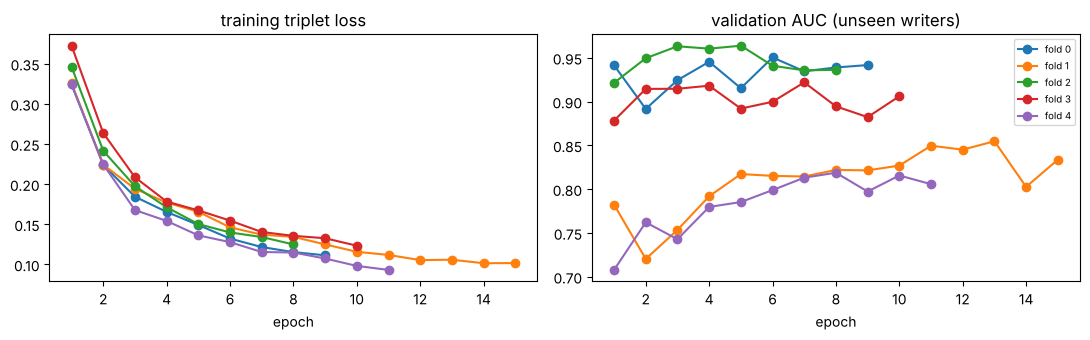

In [6]:
hist = pd.concat(histories)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for k, h in hist.groupby("fold"):
    axes[0].plot(h.epoch, h["train loss"], marker="o", label=f"fold {k}")
    axes[1].plot(h.epoch, h["validation"], marker="o", label=f"fold {k}")
axes[0].set_title("training triplet loss"); axes[1].set_title("validation AUC (unseen writers)")
for ax in axes: ax.set_xlabel("epoch")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

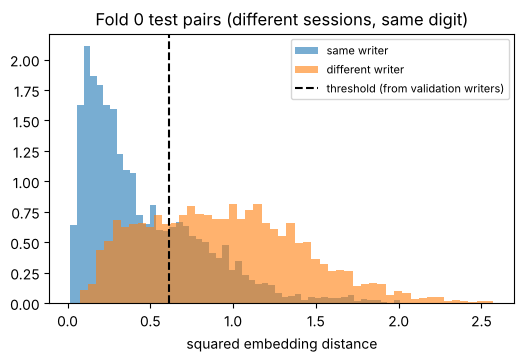

In [7]:
dist, label = fold0
plt.figure(figsize=(6, 3.5))
plt.hist(dist[label == 1], bins=50, alpha=0.6, label="same writer", density=True)
plt.hist(dist[label == 0], bins=50, alpha=0.6, label="different writer", density=True)
thr = results.query("fold == 0 and pairs == 'diff_session' and model == 'Siamese'").threshold.iloc[0]
plt.axvline(thr, color="black", linestyle="--", label="threshold (from validation writers)")
plt.xlabel("squared embedding distance")
plt.title("Fold 0 test pairs (different sessions, same digit)")
plt.legend(fontsize=8)
plt.show()

### By digit (different-session pairs)

In [8]:
by_digit = pd.DataFrame(digit_rows).pivot(index="fold", columns="digit", values="AUC")
print(by_digit.round(3))
print("\nmean AUC by digit:")
print(by_digit.agg(["mean", "std"]).round(3))

digit      0      1      2      3      4
fold                                    
0      0.748  0.830  0.864  0.766  0.812
1      0.942  0.891  0.970  0.920  0.956
2      0.830  0.790  0.783  0.818  0.667
3      0.953  0.948  0.921  0.966  0.952
4      0.922  0.811  0.945  0.952  0.932

mean AUC by digit:
digit      0      1      2      3      4
mean   0.879  0.854  0.897  0.884  0.864
std    0.088  0.064  0.075  0.088  0.125


## Task 4: what kind of generalisation, and is it optimistic?

### Leakage check: how pairs are drawn changes the answer

In [9]:
leak = (results[results.model == "Siamese"]
        .groupby("pairs")[["AUC", "EER", "accuracy"]].mean()
        .loc[["same_session", "diff_session", "diff_digit"]].round(3))
leak

,AUC,EER,accuracy
pairs,,,
same_session,0.997,0.023,0.862
diff_session,0.876,0.199,0.791
diff_digit,0.752,0.312,0.601


### Notes for the report (write in your own words)

**Siamese network: writer-disjoint folds.** This measures *open-set* generalisation: can the
network match handwriting of people it has never seen? Positives always come from different
sessions, so it also has to cope with session changes.

**CNN (Task 2): session split** (train sessions 1–3, validate 4, test 5). Identification needs every
writer during training, so writers cannot be held out. This measures generalisation to a **new
recording occasion of known writers**.

**Sources of optimism or leakage to discuss:**

- **Random splits:** the CNN scored 0.999 with a random split against about 0.56–0.64 by session
  (Task 2), and same-session pairs here score higher than different-session pairs. Near-duplicate
  replicates make any random split badly optimistic.
- **Validation re-use:** the validation writers or session choose the stopping epoch, the threshold
  and (Task 5) the hyperparameters, so validation scores are optimistic. Test scores are not used
  for any choice in this notebook.
- **Test results seen earlier:** in Task 2 the session-5 test accuracy was looked at when deciding
  to add augmentation. That is mild test-set reuse and should be stated.
- **Small test groups:** each fold tests only 4 writers, so negatives come from just 3 other
  people. Fold-to-fold spread is large (see the AUC per fold), so report mean ± sd, not one fold.
- **Simulated data:** clean, centred images with parametric session shifts. Real handwriting
  (other pens, paper, scanning, many more writers) would almost certainly be harder.